# Frozen transcriptomic representations predict drug sensitivity in held-out cancer cell lines

**Scientific question.** Does a frozen BridgeRNA representation of baseline cell-line expression contain information that predicts measured IC50 variation for known drug screens in cell lines excluded from downstream readout training?

**Hypothesis.** Under identical held-out-cell-line splits and a common linear readout, Bridge-45.6M will yield higher within-screen out-of-fold Pearson correlation than conventional expression summaries and alternative frozen transcriptomic representations.

This analysis evaluates **known drug screen → unseen cell line** prediction. It does not test unseen compounds, post-treatment expression, causal biomarkers, clinical efficacy, or drug repurposing. Data derive from the released [BulkFormer drug-response record](https://doi.org/10.5281/zenodo.15744294).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
TABLES = ROOT / "cached_evidence" / "tables"
FIGURES = ROOT / "figures"
PROVENANCE = json.loads((ROOT / "cached_evidence" / "provenance.json").read_text())
assert PROVENANCE["verification"]["status"] == "passed"
PROVENANCE["cohort"]

{'broad_lineages': 27,
 'cell_lines': 700,
 'folds': 5,
 'gdsc_drug_ids': 295,
 'pubchem_compounds': 255,
 'response_observations': 212299,
 'test_cell_lines_per_fold': 140,
 'version_specific_screens': 355}

## Data and cohort

The cohort contains 700 distinct DepMap cancer cell-line models spanning 27 broad lineages, not repeated samples from one tumor. One released baseline expression profile per cell line is reused across 212,299 measured responses from 355 GDSC1/GDSC2 version-specific screens (295 drug identifiers; 255 PubChem compounds). Screens contain 134–697 observed cell lines (median 658).

Five deterministic, lineage-stratified folds hold out 140 complete cell lines each. No response from a held-out cell line enters downstream readout fitting. Because screens reuse cell lines and some compounds occur in both GDSC versions, the 355 screens and 212,299 responses are not independent biological replicates.

## Preprocessing and representations

The raw and PCA controls use all 19,098 released processed expression features unchanged. The matrix contains negative values and its exact transform is undocumented. For frozen-model inference, negative values were clipped to zero and remaining values were treated as `log2(TPM+1)` before multiplication by `ln(2)`. This is an explicit approximation and is not equivalent to canonical natural `log1p(TPM)` if the release was batch-corrected or otherwise transformed.

Bridge uses its frozen standard 512-dimensional sample representation with 15,130 of 15,165 canonical genes observed; 35 absent genes are zero-filled. Local BulkFormer controls use frozen mean-pooled final contextual-token representations (259 dimensions for BulkFormer-50M; 643 for BulkFormer-147M). Conventional controls include raw expression, PCA-1–8 and PCA-16/32/64/128/256/512, and PCA-128 concatenated with Bridge. PCA is independently fitted on standardized training-fold expression and applied to held-out cells; PCA scores, not loadings, enter ridge regression.

## Evaluation

Every representation uses the same standardized multi-output ridge framework with a separate output for each version-specific screen. The fixed penalty is `alpha = 1000 × dimensions / 128`. Missing training responses receive one-pass training-screen-mean completion; depending on screen and fold, 0.18%–81.43% of training rows are completed. Predictions are assembled out of fold.

PCC, SCC, and RMSE are calculated within each screen and summarized as unweighted means across 355 screens; median PCC is also reported. Paired intervals use 10,000 bootstrap resamples of screens and are descriptive because screens share cell lines and repeated compounds. One split partition and one representation extraction per model are available, so no across-seed mean or SD is reported.

In [2]:
primary = pd.read_csv(TABLES / "primary_results.csv")
metrics = pd.read_csv(TABLES / "per_drug_metrics.csv")
recalculated = metrics.groupby("representation", as_index=False).agg(
    mean_pcc=("pcc", "mean"), median_pcc=("pcc", "median"),
    mean_scc=("scc", "mean"), rmse=("rmse", "mean"),
    evaluable_drugs=("screen_id", "nunique"))
check = primary.merge(recalculated, on="representation", suffixes=("_saved", "_recalculated"))
for metric in ["mean_pcc", "median_pcc", "mean_scc", "rmse"]:
    assert (check[f"{metric}_saved"] - check[f"{metric}_recalculated"]).abs().max() < 1e-12
primary.sort_values("mean_pcc", ascending=False).round(3)

,representation,mean_pcc,median_pcc,mean_scc,rmse,evaluable_drugs
0,bridge_45.6m,0.448,0.461,0.424,1.235,355
2,bulkformer_50m,0.438,0.450,0.414,1.238,355
1,bulkformer_147m,0.436,0.452,0.416,1.244,355
11,pca_4,0.360,0.363,0.353,1.286,355
9,pca_3,0.359,0.364,0.353,1.287,355
12,pca_5,0.357,0.364,0.356,1.289,355
14,pca_6,0.319,0.331,0.367,1.358,355
17,pca_8,0.313,0.325,0.382,1.387,355
7,pca_2,0.307,0.325,0.292,1.303,355
16,pca_7,0.304,0.319,0.375,1.396,355


## Results

Bridge-45.6M achieved mean per-screen PCC 0.448 (median 0.461), mean SCC 0.424, and mean per-screen RMSE 1.235. Locally evaluated BulkFormer-50M and BulkFormer-147M achieved mean PCC 0.438 and 0.436. The Bridge differences were small: mean ΔPCC 0.0102 and 0.0120, with Bridge higher on 71.8% and 74.6% of screens, respectively. The published BulkFormer PCC 0.373 is literature context only because its final folds, readout, drug grouping, and aggregation cannot be reconstructed.

In [3]:
paired = pd.read_csv(TABLES / "paired_comparisons.csv")
paired.round(4)

,left,right,n_drugs,mean_delta_pcc,median_delta_pcc,ci95_low,ci95_high,fraction_left_better
0,bridge_45.6m,pca_4,355,0.0883,0.0655,0.0810,0.0959,0.9634
1,bridge_45.6m,pca_512,355,0.4176,0.4291,0.4042,0.4308,1.0000
2,bridge_45.6m,bulkformer_50m,355,0.0102,0.0088,0.0083,0.0122,0.7183
3,bridge_45.6m,bulkformer_147m,355,0.0120,0.0117,0.0092,0.0147,0.7465
4,pca128_bridge,pca_128,355,0.1958,0.1960,0.1840,0.2075,0.9944


### PCA dimensionality sensitivity

The complete exploratory PCA curve has an interior optimum at PCA-4 (mean PCC 0.360); PCA-3 and PCA-5 achieve 0.359 and 0.357. Bridge exceeds PCA-4 by mean ΔPCC 0.0883 (95% screen-bootstrap interval 0.0810–0.0959) and is higher on 342 of 355 screens (96.3%). Because component count was expanded after inspecting the original PCA-128/PCA-512 controls, PCA-4 is the **best observed exploratory setting**, not a prospectively selected hyperparameter.

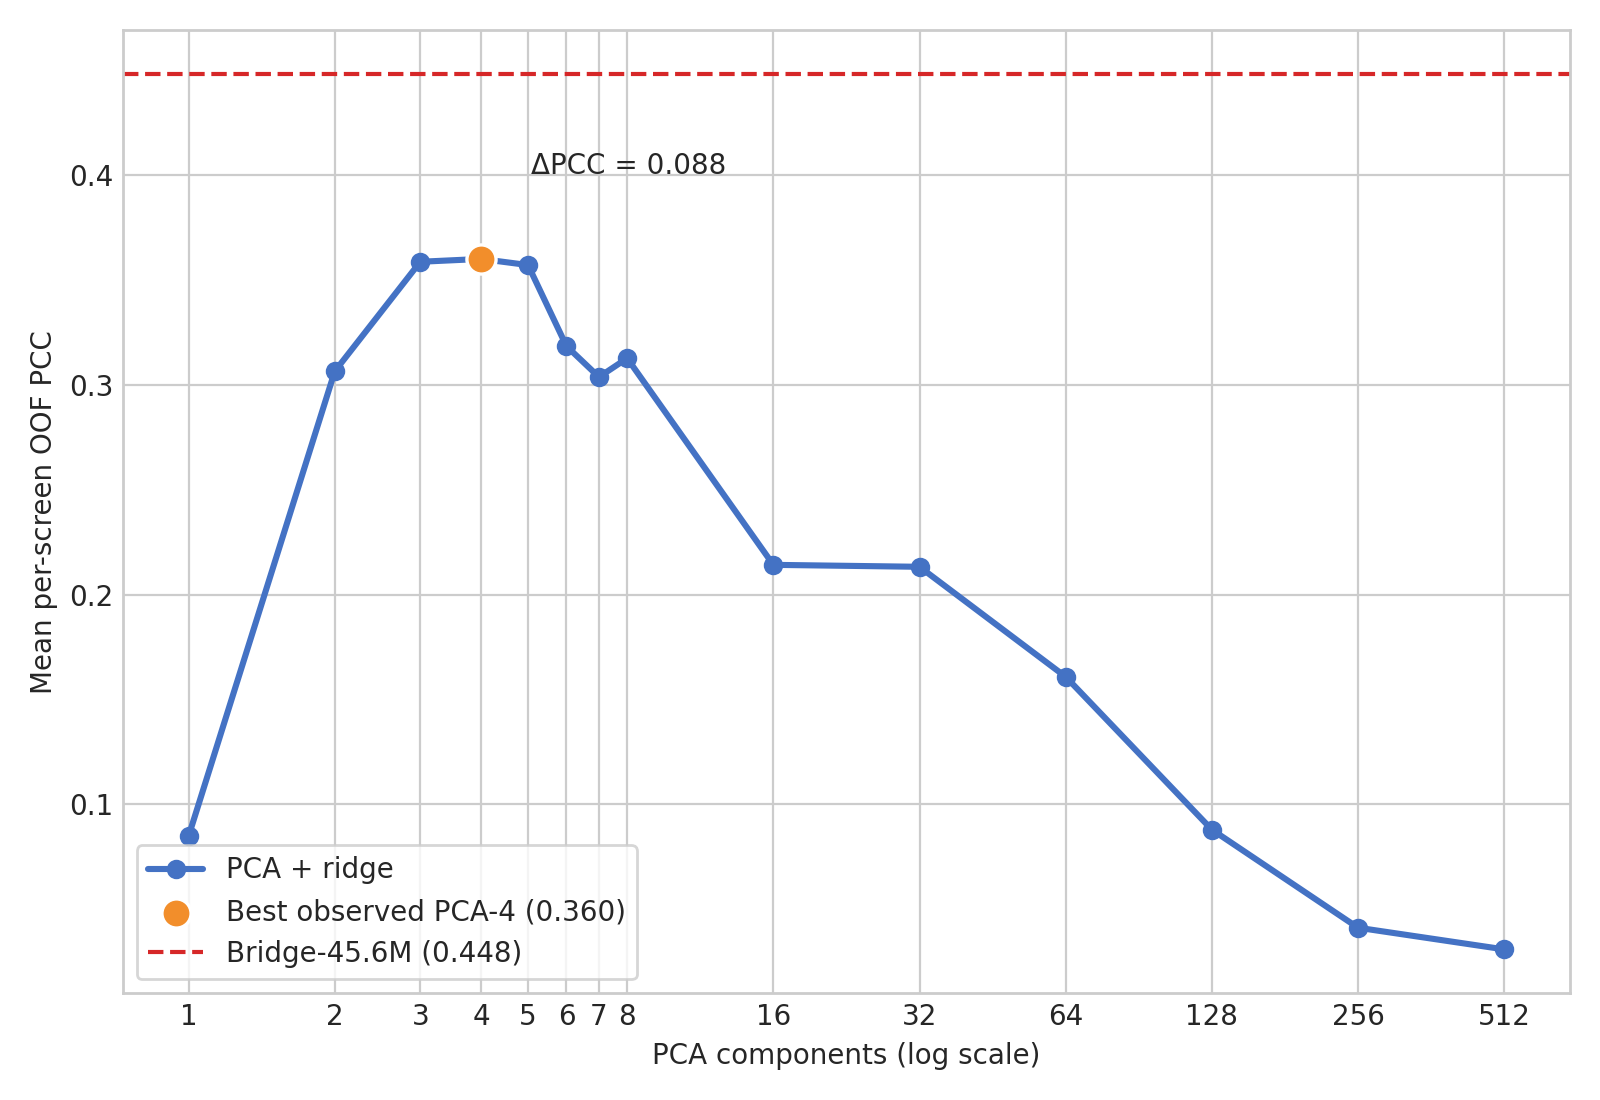

,components,mean_pcc,median_pcc,mean_scc,rmse,evaluable_drugs
0,1,0.085,0.098,0.108,1.377,355
1,2,0.307,0.325,0.292,1.303,355
2,3,0.359,0.364,0.353,1.287,355
3,4,0.360,0.363,0.353,1.286,355
4,5,0.357,0.364,0.356,1.289,355
5,6,0.319,0.331,0.367,1.358,355
6,7,0.304,0.319,0.375,1.396,355
7,8,0.313,0.325,0.382,1.387,355
8,16,0.214,0.184,0.406,1.761,355
9,32,0.213,0.167,0.425,1.891,355


In [4]:
pca = pd.read_csv(TABLES / "pca_component_sensitivity.csv")
display(Image(filename=str(FIGURES / "pca_component_sensitivity.png")))
pca.round(3)

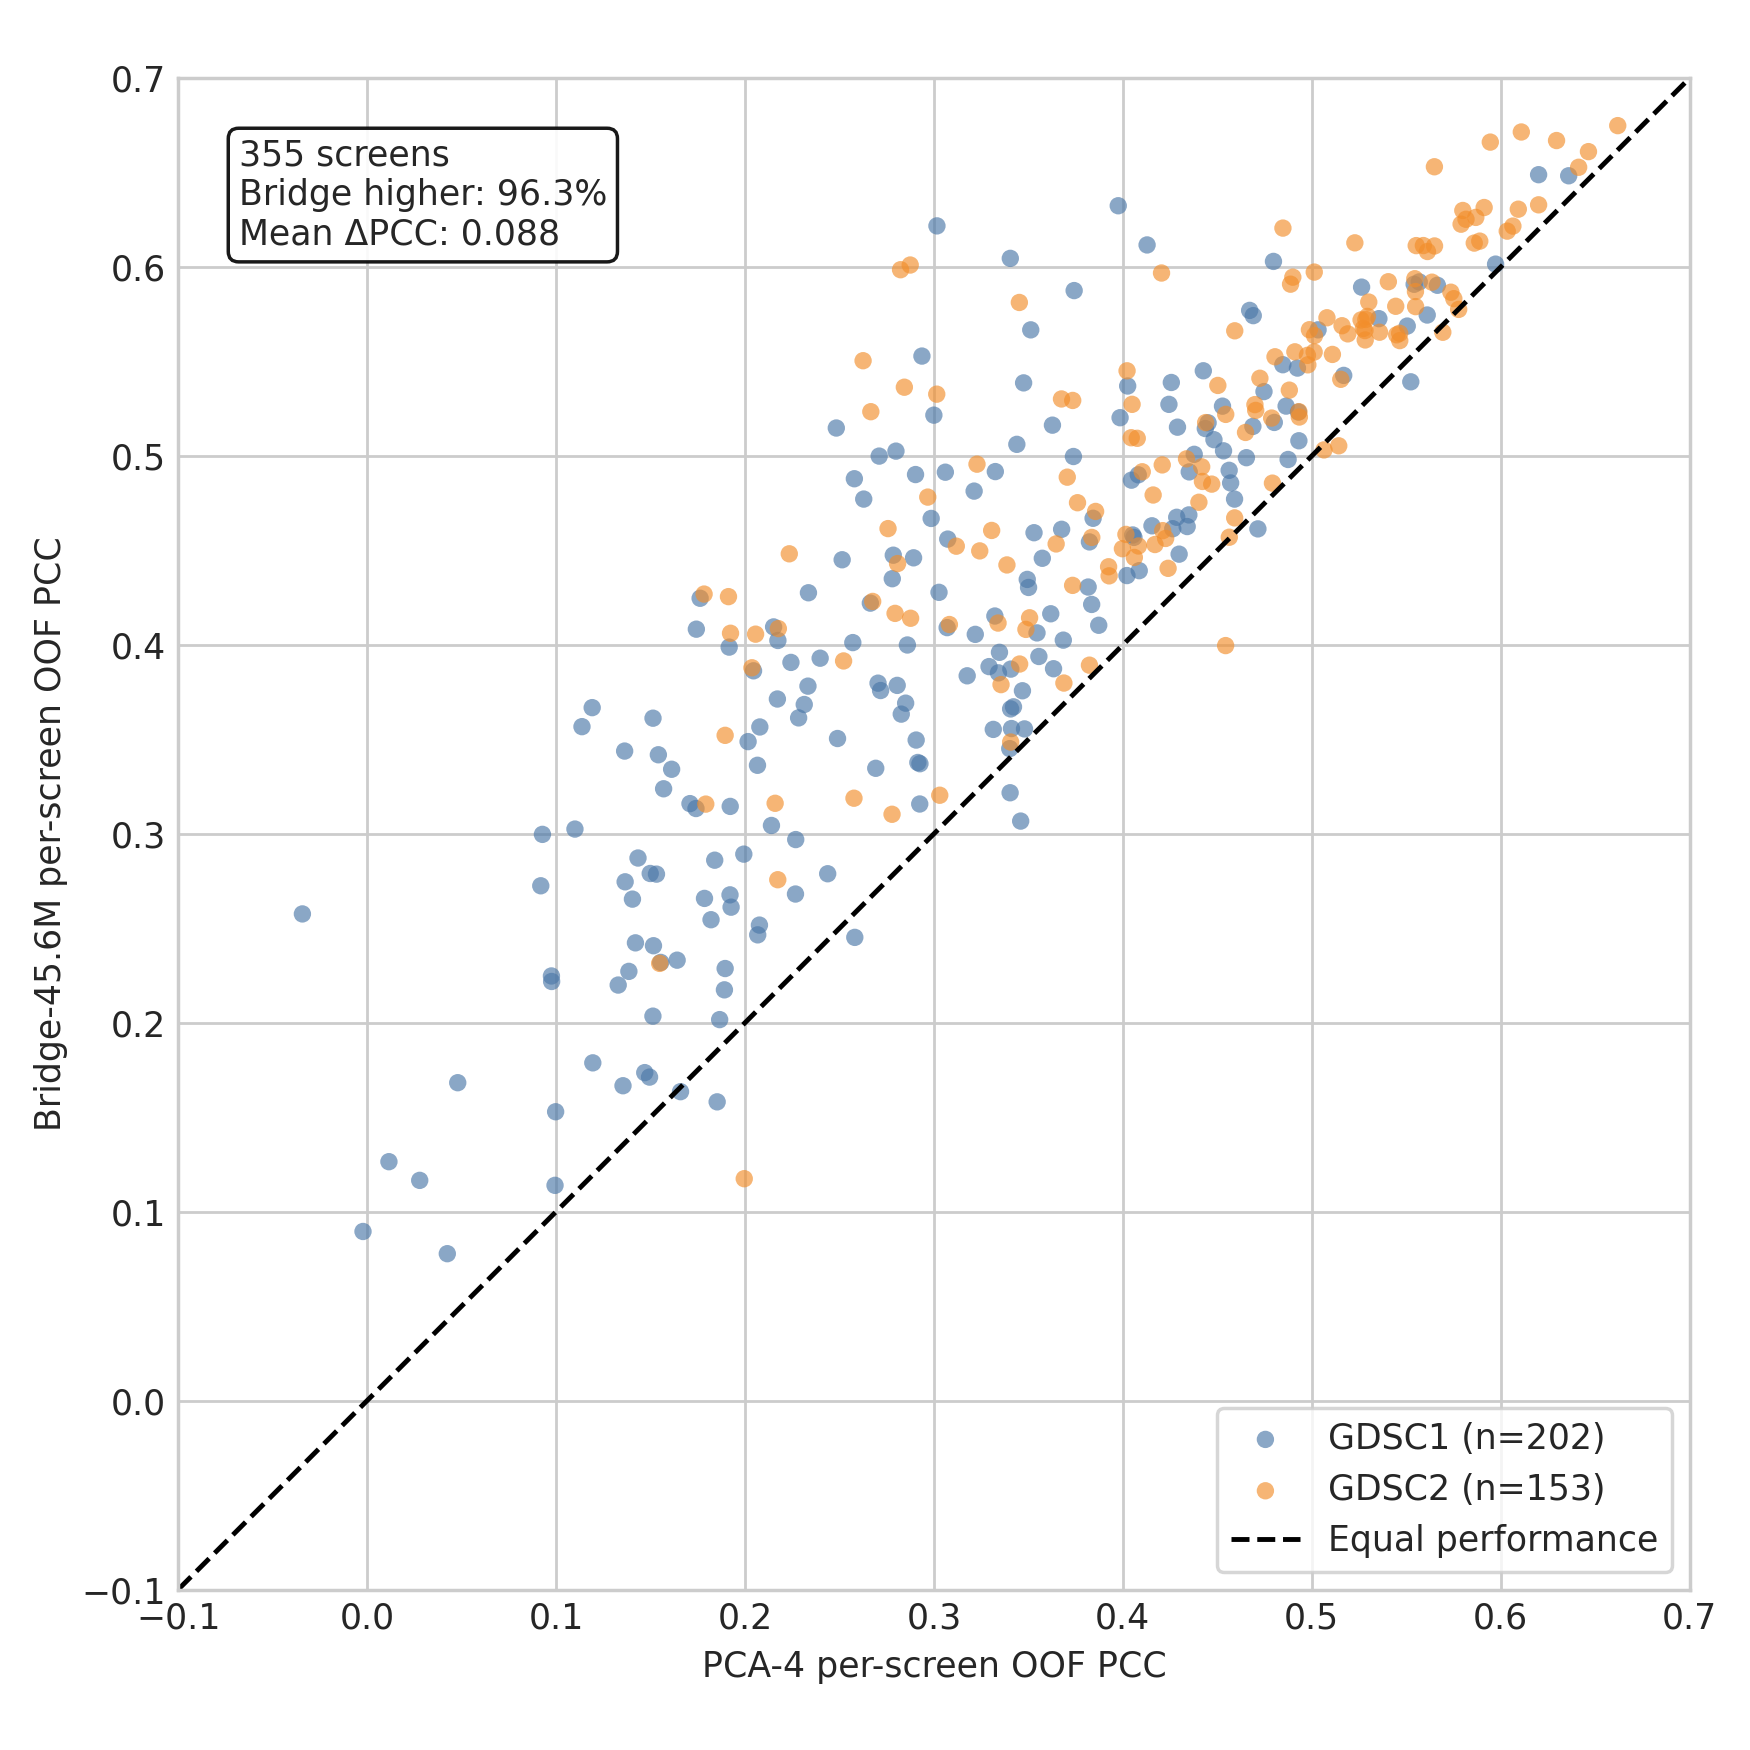

,screens,mean_bridge_pcc,mean_pca4_pcc,mean_delta_pcc
dataset_version,,,,
GDSC1,202,0.401,0.305,0.097
GDSC2,153,0.510,0.434,0.077


In [5]:
per_screen = pd.read_csv(TABLES / "bridge_vs_pca4_per_screen.csv")
assert len(per_screen) == 355 and per_screen["screen_id"].is_unique
display(Image(filename=str(FIGURES / "bridge_vs_pca4_per_screen.png")))
per_screen.groupby("dataset_version").agg(
    screens=("screen_id", "size"),
    mean_bridge_pcc=("bridge_pcc", "mean"),
    mean_pca4_pcc=("pca4_pcc", "mean"),
    mean_delta_pcc=("delta_pcc", "mean"),
).round(3)

### Negative and metric-dependent findings

Raw expression has mean PCC 0.196 but the highest mean SCC, 0.440, showing that rank association, linear correlation, and absolute error support different conclusions. PCA-128 concatenated with Bridge reaches mean PCC 0.284, below Bridge alone, so this run does not establish useful complementarity from appending PCA features.

## Limitations

- The source expression transform is undocumented; frozen-model inputs use an approximate conversion that may affect architectures differently.
- Exact Bridge pretraining exposure is unresolved because GEO/SRA sample and study accessions are unavailable.
- Results use one deterministic five-fold partition; screen-bootstrap intervals do not capture split variability and may understate dependence among screens.
- Mean-completed targets and a fixed, dimension-scaled ridge penalty were not replaced by observed-only fitting and nested training-only hyperparameter selection.
- Every screen has training observations and its own output; unseen-drug generalization is not tested.
- The local BulkFormer comparison is not a reproduction of the published PCC 0.373.

## Conclusion

Frozen Bridge representations contain baseline cellular-state information that predicts IC50 variation in held-out cell lines under a common lightweight readout. Bridge is higher than every tested PCA dimension and shows a small local advantage over both frozen BulkFormer checkpoints, but the evidence supports representation utility under this protocol—not state-of-the-art pharmacogenomic prediction, unseen-drug generalization, or direct improvement over the published BulkFormer result.